# Phase 4: Machine-learning data

Build features for historical S&P 500 members using adjusted prices from 2010–2024. For each formation month, membership and features are known at the **previous trading close**, before the assumed formation-close execution. The target is the stock's adjusted-price return from the formation close to the next month-end close. The panel is validated before fitting a Ridge Regression baseline and evaluating a chronological test period.

Historical membership and prices are reconstructed from third-party data; gaps, ticker mapping, corporate actions and missing delisting outcomes may still introduce bias.


In [9]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
if not (root / "src").is_dir(): root = root.parent
sys.path.insert(0, str(root))
from src.data_loader import load_historical_prices, load_historical_membership
from src.ml_features import build_ml_dataset, FEATURE_COLUMNS
data = root / "data/sp500_historical_2010_2024"
prices = load_historical_prices(data / "prices_long.parquet")
membership = load_historical_membership(data / "members.parquet")
metadata = json.loads((data / "metadata.json").read_text())
print("Source:", metadata["source_repository"])
print("Price range:", prices.index.min().date(), "to", prices.index.max().date())
print("Historical symbols:", len(prices.columns), "| Membership dates:", membership.date.nunique())
membership.head()


Source: https://github.com/Johnbrick123/sp500-data
Price range: 2010-01-04 to 2024-12-31
Historical symbols: 797 | Membership dates: 1088


,date,ticker
0,2009-12-30,A
1,2009-12-30,AABA
2,2009-12-30,AAPL
3,2009-12-30,ABT
4,2009-12-30,ACS-201002


## Inspect missing history

A stock can lack prices because it was not yet listed, its ticker changed, or a download failed. These cases must not be filled as if the price stayed constant. The coverage table is diagnostic, not proof that a missing record is a genuine absence.

In [10]:
coverage = pd.DataFrame({"ticker": prices.columns, "observations": prices.notna().sum().values})
print("Symbols with at least one price:", (coverage.observations > 0).sum())
print("Missing daily price cells:", f"{prices.isna().mean().mean():.1%}")
coverage.sort_values("observations").head(10)


Symbols with at least one price: 797
Missing daily price cells: 17.4%


,ticker,observations
394,JAVA-201001,16
11,ACS-201002,24
108,BNI-201002,29
632,RX-201002,37
561,PBG-201002,38
89,BDK-201003,48
47,AMTM,69
100,BJS-201004,80
790,XTO-201006,121
479,MIL-201007,133


## Four features and a target

All feature windows end at the signal close, the trading day before formation. Prices must be observed throughout each window; missing values are not filled.

| Feature | Definition at the signal close | Hypothesis |
|---|---|---|
| `momentum_6m` | Price return over 126 trading days | Recent winners may keep outperforming |
| `momentum_12_1` | Price 21 sessions ago divided by price 252 sessions ago, minus one | Medium-term momentum |
| `volatility_63d` | Standard deviation of 63 daily returns × √252 | Risk may relate to future performance |
| `reversal_21d` | Negative of the return over 21 trading days | Short-term reversals may occur |

The target `next_month_return` is adjusted price at the next month-end divided by adjusted price at formation, minus one. Missing values remain visible before constructing the complete-case dataset; missing outcomes, especially around delistings, can bias results.


In [11]:
all_rows = build_ml_dataset(prices, membership)
columns = FEATURE_COLUMNS + ["next_month_return"]
print(f"Historical member-month rows: {len(all_rows):,}")
print("Missing values by field:")
print(all_rows[columns].isna().sum())
features = all_rows.dropna(subset=columns).copy()
print(f"Complete labeled observations: {len(features):,} across {features.index.get_level_values('ticker').nunique()} symbols")
features.head()


Historical member-month rows: 90,522
Missing values by field:
momentum_6m          3216
momentum_12_1        6444
volatility_63d       1599
reversal_21d          520
next_month_return     659
dtype: int64
Complete labeled observations: 83,442 across 763 symbols


momentum_6m  momentum_12_1  volatility_63d  \
formation_date ticker                                               
2011-01-31     A          0.467240       0.487335        0.242449   
               AABA       0.140490       0.106596        0.256337   
               AAPL       0.306511       0.693689        0.191142   
               ABT       -0.056835      -0.080851        0.126397   
               ADBE       0.131267      -0.041176        0.262890   

                       reversal_21d  next_month_return signal_date  
formation_date ticker                                               
2011-01-31     A           0.017030           0.005977  2011-01-28  
               AABA        0.046960           0.017370  2011-01-28  
               AAPL       -0.033232           0.040935  2011-01-28  
               ABT         0.031829           0.065102  2011-01-28  
               ADBE       -0.049080           0.043873  2011-01-28

## Validate the panel and split by time

- **Train:** January 2011–November 2018.
- **Validation:** January 2019–November 2021.
- **Test:** January 2022–November 2024.

December 2018 and December 2021 are excluded because their targets extend into the next split. Stocks from the same formation month stay together. The tests check structure, timing, missingness, historical membership, and a small deterministic sample of feature and target calculations; they cannot establish that all vendor prices and membership records are accurate. Phase 3 results for the later years have been inspected, so this test is not a completely untouched research sample.

In [12]:
from src.data_loader import constituents_as_of
assert all_rows.index.is_unique
assert not all_rows.index.to_frame(index=False).isna().any().any()
assert (all_rows["signal_date"] < all_rows.index.get_level_values("formation_date")).all()
assert np.isfinite(features[columns].to_numpy()).all()
assert features["volatility_63d"].ge(0).all()
assert features["next_month_return"].ge(-1).all()
# Independently inspect formulas and membership at sampled, complete rows.
for k in np.linspace(0, len(features) - 1, 7, dtype=int):
    (date, ticker), row = features.iloc[[k]].iloc[0].name, features.iloc[k]
    signal = row["signal_date"]
    assert ticker in constituents_as_of(membership, signal)
    i = prices.index.get_loc(signal)
    series = prices[ticker]
    assert np.isclose(row["momentum_6m"], series.iloc[i] / series.iloc[i-126] - 1)
    assert np.isclose(row["momentum_12_1"], series.iloc[i-21] / series.iloc[i-252] - 1)
    assert np.isclose(row["reversal_21d"], 1 - series.iloc[i] / series.iloc[i-21])
    assert np.isclose(row["volatility_63d"], series.pct_change(fill_method=None).iloc[i-62:i+1].std() * np.sqrt(252))
    end_prices = prices.resample("ME").last(skipna=False)
    next_date = date + pd.offsets.MonthEnd(1)
    assert np.isclose(row["next_month_return"], end_prices.at[next_date, ticker] / end_prices.at[date, ticker] - 1)
print("Panel checks passed: unique keys, finite values, timing, membership, and sampled formulas.")

dates = features.index.get_level_values("formation_date")
train = features.loc[(dates >= "2011-01-01") & (dates <= "2018-11-30")].copy()
validation = features.loc[(dates >= "2019-01-01") & (dates <= "2021-11-30")].copy()
test = features.loc[(dates >= "2022-01-01") & (dates <= "2024-11-30")].copy()
for name, frame, expected_start, expected_end in [("Train",train,"2011-01-31","2018-11-30"),("Validation",validation,"2019-01-31","2021-11-30"),("Test",test,"2022-01-31","2024-11-30")]:
    d = frame.index.get_level_values("formation_date")
    assert d.min() == pd.Timestamp(expected_start) and d.max() == pd.Timestamp(expected_end)
    print(f"{name}: {len(frame):,} rows, {d.nunique()} months, {d.min().date()} to {d.max().date()}")
assert not ({pd.Timestamp("2018-12-31"), pd.Timestamp("2021-12-31")} & (set(train.index.get_level_values(0)) | set(validation.index.get_level_values(0)) | set(test.index.get_level_values(0))))

Panel checks passed: unique keys, finite values, timing, membership, and sampled formulas.
Train: 47,347 rows, 95 months, 2011-01-31 to 2018-11-30
Validation: 17,562 rows, 35 months, 2019-01-31 to 2021-11-30
Test: 17,525 rows, 35 months, 2022-01-31 to 2024-11-30


## Ridge Regression baseline

Ridge fits a linear relationship while penalizing large coefficients. Each pipeline learns standardization and model coefficients from the **training split only**. We select alpha using validation mean squared error; the selected pipeline is then fitted on training data only and evaluated on test data. No random splitting is used. The test period has already been inspected during Phase 3 and earlier research. These are prediction metrics, not portfolio returns.

In [13]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

X_train, y_train = train[FEATURE_COLUMNS], train["next_month_return"]
X_val, y_val = validation[FEATURE_COLUMNS], validation["next_month_return"]
X_test, y_test = test[FEATURE_COLUMNS], test["next_month_return"]
alpha_grid = [0.1, 1, 10, 100, 1000]
validation_rows = []
for alpha in alpha_grid:
    model = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    validation_rows.append({"alpha": alpha, "validation_mse": mean_squared_error(y_val, pred)})
validation_results = pd.DataFrame(validation_rows).set_index("alpha").sort_values("validation_mse")
best_alpha = validation_results.index[0]
print("Selected alpha:", best_alpha)
validation_results

Selected alpha: 0.1


,validation_mse
alpha,
0.1,0.009879
1.0,0.009879
10.0,0.009879
100.0,0.009879
1000.0,0.009882


In [14]:
# Refit on the original training period only; validation chooses alpha.
final_model = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha))
final_model.fit(X_train, y_train)
test_predictions = final_model.predict(X_test)
benchmarks = {"Ridge": test_predictions, "Zero return": np.zeros(len(y_test)), "Training mean": np.full(len(y_test), y_train.mean())}
metrics = pd.DataFrame({name: {"MSE": mean_squared_error(y_test,pred), "MAE": mean_absolute_error(y_test,pred), "R²": r2_score(y_test,pred)} for name,pred in benchmarks.items()}).T
metrics

,MSE,MAE,R²
Ridge,0.008685,0.070246,-0.002499
Zero return,0.008704,0.070160,-0.004705
Training mean,0.008671,0.070180,-0.000817


Prediction error alone does not show whether the model ranks stocks well. The analysis below evaluates the cross-sectional rankings and a real portfolio simulation. Missing outcomes, reconstructed membership and previously inspected holdout years remain limitations.

## Monthly rank information coefficient (IC)

For each formation month, Spearman rank correlation compares predicted and subsequently realized returns across stocks with available outcomes. +1 means perfect ordering, 0 indicates no monotonic rank relationship, and −1 means reversed ordering. Each month receives equal weight in the summary. Months with fewer than three valid pairs or constant values have undefined IC and are excluded from the mean; the number of stocks is reported. These are test-period results, not a measure of trading profit.

In [15]:
from src.experiment import monthly_rank_ic, predict_month_scores
predicted = pd.Series(test_predictions, index=test.index, name="predicted_return")
rank_ic = monthly_rank_ic(predicted, y_test)
valid_ic = rank_ic["rank_ic"].dropna()
assert len(rank_ic) == test.index.get_level_values("formation_date").nunique()
print(f"Months: {len(rank_ic)} | defined IC: {len(valid_ic)} | median stocks: {rank_ic.n_stocks.median():.0f}")
print(f"Mean IC: {valid_ic.mean():.4f} | median IC: {valid_ic.median():.4f} | positive months: {(valid_ic > 0).mean():.1%}")
rank_ic.head()

Months: 35 | defined IC: 35 | median stocks: 501
Mean IC: -0.0387 | median IC: -0.0776 | positive months: 40.0%


,rank_ic,n_stocks
formation_date,,
2022-01-31,-0.097868,502
2022-02-28,-0.190623,502
2022-03-31,-0.231196,501
2022-04-30,0.058468,502
2022-05-31,-0.358116,502


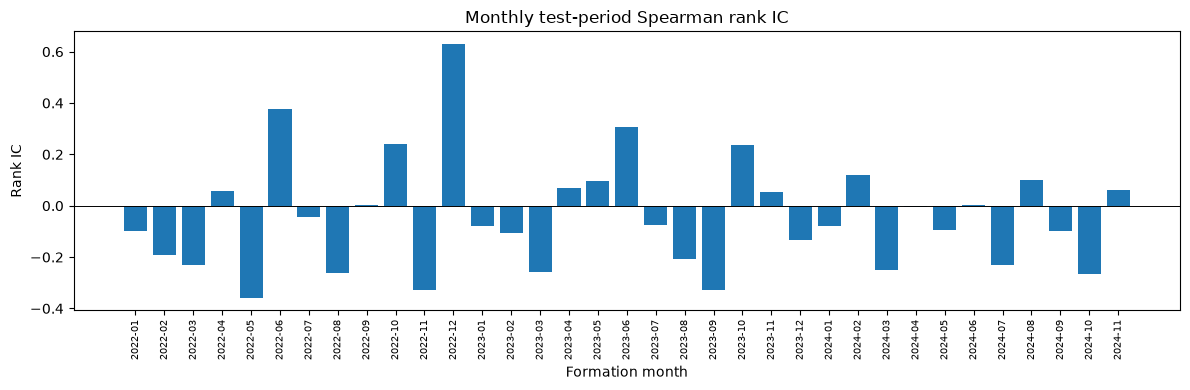

In [16]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(rank_ic.index.strftime("%Y-%m"), rank_ic["rank_ic"])
ax.set_title("Monthly test-period Spearman rank IC")
ax.axhline(0, color="black", linewidth=0.7)
ax.set_xlabel("Formation month"); ax.set_ylabel("Rank IC")
ax.tick_params(axis="x", labelsize=7, rotation=90)
plt.tight_layout(); plt.show()

## Out-of-sample portfolio backtest

At each formation close from January 2022 through November 2024, buy the five historical index members with the highest model-predicted next-month returns. Features, membership and the fitted model are known before execution. The portfolio holds positions until the next rebalance and pays 10 bps per dollar bought or sold, including its initial purchases. A momentum-12–1 comparator uses the same feature-complete investable universe and costs. **Candidate selection does not filter on future outcome availability.** Missing held prices stop the simulation instead of being filled. Exact execution at the close and target weights are simplifying assumptions, and reconstructed prices, unmodeled delisting proceeds and small sample size can still bias results.
Discovery Series C (DISCK) converted one-for-one into WBD on 2022-04-11 ([SEC filing](https://www.sec.gov/Archives/edgar/data/1437107/000119312522103051/d328161d8k.htm)). We model this documented conversion as a non-trade and combine the resulting positions. Rank IC excludes missing labels, including a DISCK label spanning the conversion. Other unmodeled corporate actions still cause a missing-price error rather than an assumed return.


In [17]:
from src.backtest import run_factor_backtest
from src.metrics import calculate_performance_metrics

# Provide one year of warm-up because the generalized runner starts after 12 months.
test_prices = prices.loc["2021-01-01":"2024-12-31"]
def ml_scores(current_prices, current_returns, formation_date):
    signal_date = current_prices.index[-2]
    return predict_month_scores(final_model, all_rows, formation_date, signal_date, FEATURE_COLUMNS)

def momentum_scores(current_prices, current_returns, formation_date):
    # Same candidates as Ridge: do not use the future return for filtering.
    eligible = predict_month_scores(final_model, all_rows, formation_date, current_prices.index[-2], FEATURE_COLUMNS).index
    return all_rows.xs(formation_date, level="formation_date").loc[eligible, "momentum_12_1"]

corporate_actions = [{"date": "2022-04-11", "old": "DISCK", "new": "WBD", "ratio": 1}]
ml_returns, ml_holdings, ml_trades = run_factor_backtest(test_prices, ml_scores, top_n=5, strategy_name="Ridge top 5", transaction_cost_bps=10, corporate_actions=corporate_actions)
mom_returns, mom_holdings, mom_trades = run_factor_backtest(test_prices, momentum_scores, top_n=5, strategy_name="Momentum 12–1 top 5", transaction_cost_bps=10, corporate_actions=corporate_actions)
assert ml_returns.index.equals(mom_returns.index)
assert len(ml_returns) == 35
assert ml_holdings.holdings.map(len).eq(5).all() and mom_holdings.holdings.map(len).eq(5).all()
assert ml_holdings.formation_date.min() == pd.Timestamp("2022-01-31")
assert ml_holdings.formation_date.max() == pd.Timestamp("2024-11-30")
portfolio_metrics = pd.DataFrame({"Ridge top 5": calculate_performance_metrics(ml_returns), "Momentum 12–1 top 5": calculate_performance_metrics(mom_returns)}).T
portfolio_metrics["Ending wealth ($1)"] = [(1 + ml_returns).prod(), (1 + mom_returns).prod()]
portfolio_metrics["Average monthly traded value"] = [ml_trades.gross_traded_value.mean(), mom_trades.gross_traded_value.mean()]
portfolio_metrics.round(4)

,CAGR,Annual Return,Annual Volatility,Sharpe Ratio,Max Drawdown,Ending wealth ($1),Average monthly traded value
Ridge top 5,-0.2989,-0.2619,0.4130,-0.6341,-0.7230,0.3549,1.3196
Momentum 12–1 top 5,0.1480,0.2045,0.3685,0.5551,-0.2663,1.4958,0.7509


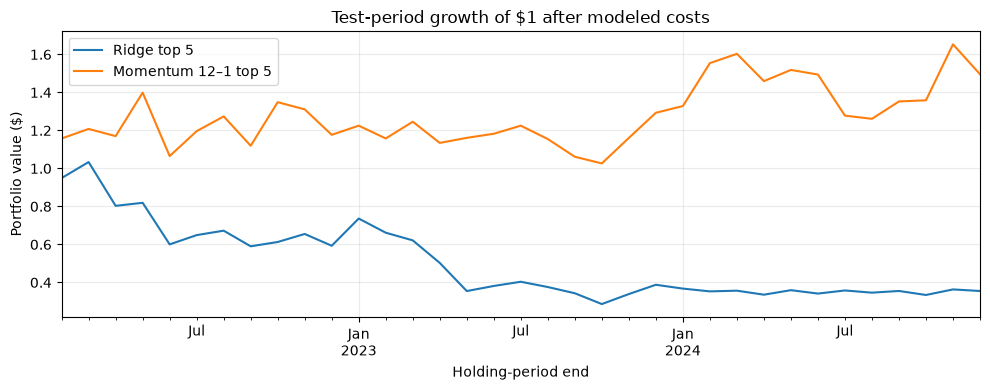

,formation_date,holdings
0,2022-01-31,"[MRNA, TSLA, ETSY, NFLX, TER]"
1,2022-02-28,"[PYPL, TSLA, TER, META, NCLH]"
2,2022-03-31,"[ETSY, WBD, DISCK, LVS, SEDG]"
3,2022-04-30,"[EPAM, NFLX, ETSY, PYPL, NLSN]"
4,2022-05-31,"[UA, UAA, NCLH, DISH, CCL]"


In [18]:
wealth = pd.DataFrame({"Ridge top 5": (1 + ml_returns).cumprod(), "Momentum 12–1 top 5": (1 + mom_returns).cumprod()})
ax = wealth.plot(figsize=(10, 4), title="Test-period growth of $1 after modeled costs")
ax.set_ylabel("Portfolio value ($)"); ax.set_xlabel("Holding-period end"); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()
ml_holdings[["formation_date", "holdings"]].head()